In [2]:
# %% [markdown]
# # A2 — Data Preparation, Transformation/Reduction & First Baselines
# **Diabetes Risk Miner · DS311 · Milestone 2**
#
# Steps:
# 1. Load & clean the CDC Diabetes Health Indicators dataset (UCI id=891)
# 2. Feature engineering (row-wise, no leakage)
# 3. Leakage-safe train/test split + preprocessing pipeline
# 4. Dimensionality reduction (PCA) + mutual-information feature ranking  [Q2 prep]
# 5. Baseline models: majority-class, LogReg (±PCA), Decision Tree         [Q1]
# 6. First IF–THEN rules from the Decision Tree (support / confidence / lift) [Q3 prep]

# %%
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    f1_score, roc_auc_score, average_precision_score,
    recall_score, precision_score,
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [3]:
# %% [markdown]
# ## 1. Load & clean
# - No missing values in this dataset.
# - Lots of exact duplicate survey rows → drop them.

# %%
ds = fetch_ucirepo(id=891)
X_raw = ds.data.features.copy()
y_raw = ds.data.targets.iloc[:, 0].copy()   # 0 = no diabetes, 1 = prediabetes/diabetes

print("Raw shape:", X_raw.shape)
print("Target distribution:\n", y_raw.value_counts(normalize=True).round(3))

df = X_raw.assign(target=y_raw.values)
print("Missing values:", int(df.isna().sum().sum()))

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_before - len(df):,} duplicate rows -> {len(df):,} remain")

X = df.drop(columns="target")
y = df["target"].astype(int)
print("Positive rate after dedup:", round(y.mean(), 3))

Raw shape: (253680, 21)
Target distribution:
 Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64
Missing values: 0
Dropped 24,206 duplicate rows -> 229,474 remain
Positive rate after dedup: 0.153


In [4]:
# %% [markdown]
# ## 2. Feature engineering
# Each new feature is computed **per row**, so it cannot leak information
# across the train/test boundary.

# %%
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    d["comorbidity_count"] = d["HighBP"] + d["HighChol"] + d["Stroke"] + d["HeartDiseaseorAttack"]
    d["lifestyle_risk"] = (
        d["Smoker"] + d["HvyAlcoholConsump"]
        + (1 - d["PhysActivity"]) + (1 - d["Fruits"]) + (1 - d["Veggies"])
    )
    d["poor_health_days"] = d["MentHlth"] + d["PhysHlth"]
    d["obese"] = (d["BMI"] >= 30).astype(int)
    return d

X_fe = add_features(X)
print("Features:", X.shape[1], "->", X_fe.shape[1])

Features: 21 -> 25


In [5]:
# %% [markdown]
# ## 3. Train/test split + preprocessing pipeline
# **Split before any learned transform.** All scaling/quantile fitting happens
# inside the `Pipeline`, so during cross-validation the transforms are re-fit
# on each training fold — no leakage.

# %%
X_train, X_test, y_train, y_test = train_test_split(
    X_fe, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip to train-set quantiles to tame BMI / day-count outliers."""
    def __init__(self, lower=0.005, upper=0.995):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        A = np.asarray(X, float)
        self.lo_ = np.quantile(A, self.lower, axis=0)
        self.hi_ = np.quantile(A, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


bin_cols = [c for c in X_train.columns if X_train[c].nunique() == 2]
num_cols = [c for c in X_train.columns if c not in bin_cols]
print("Numeric/ordinal:", num_cols)
print("Binary:", bin_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("win", Winsorizer()), ("scale", StandardScaler())]), num_cols),
    ("bin", "passthrough", bin_cols),
])

Train: (183579, 25) | Test: (45895, 25)
Numeric/ordinal: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income', 'comorbidity_count', 'lifestyle_risk', 'poor_health_days']
Binary: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex', 'obese']


11 of 25 components explain >= 90% of variance


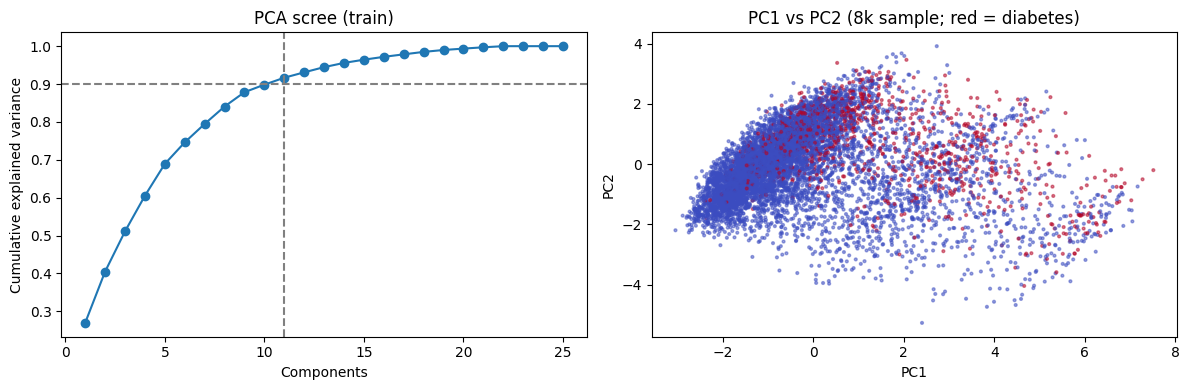


Top loadings PC1:
poor_health_days     0.462
PhysHlth             0.422
GenHlth              0.408
MentHlth             0.329
Income              -0.282
comorbidity_count    0.268
Name: PC1, dtype: float64

Top loadings PC2:
Age                  0.492
comorbidity_count    0.485
MentHlth            -0.410
poor_health_days    -0.366
PhysHlth            -0.206
Education           -0.203
Name: PC2, dtype: float64

Top loadings PC3:
lifestyle_risk       0.539
Education           -0.469
comorbidity_count   -0.331
Income              -0.315
Age                 -0.297
PhysHlth            -0.189
Name: PC3, dtype: float64


In [6]:
# %% [markdown]
# ## 4. Reduction A — PCA
# How many components keep >= 90% of the variance?

# %%
Z_train = preprocess.fit_transform(X_train)
feat_names = [n.split("__", 1)[1] for n in preprocess.get_feature_names_out()]

pca_full = PCA(random_state=SEED).fit(Z_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum_var >= 0.90) + 1)
print(f"{n_comp} of {Z_train.shape[1]} components explain >= 90% of variance")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, len(cum_var) + 1), cum_var, marker="o")
ax[0].axhline(0.90, ls="--", c="gray")
ax[0].axvline(n_comp, ls="--", c="gray")
ax[0].set(xlabel="Components", ylabel="Cumulative explained variance",
          title="PCA scree (train)")

idx = np.random.RandomState(SEED).choice(len(Z_train), min(8000, len(Z_train)), replace=False)
P2 = PCA(n_components=2, random_state=SEED).fit_transform(Z_train[idx])
ax[1].scatter(P2[:, 0], P2[:, 1], c=y_train.values[idx],
              cmap="coolwarm", s=4, alpha=0.5)
ax[1].set(xlabel="PC1", ylabel="PC2", title="PC1 vs PC2 (8k sample; red = diabetes)")
plt.tight_layout()
plt.savefig("figures/pca_scree_scatter.png", dpi=150)
plt.show()

# Show top loadings on PC1–PC3
loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    index=feat_names,
    columns=["PC1", "PC2", "PC3"],
)
for pc in loadings:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"\nTop loadings {pc}:\n{top.round(3)}")

comorbidity_count       0.0483
GenHlth                 0.0422
HighBP                  0.0364
BMI                     0.0263
HighChol                0.0213
obese                   0.0195
Age                     0.0185
DiffWalk                0.0157
PhysHlth                0.0147
HeartDiseaseorAttack    0.0121
Income                  0.0116
CholCheck               0.0107
dtype: float64


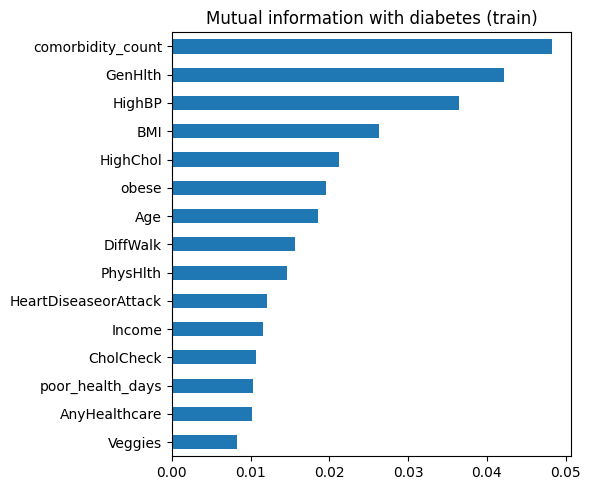

In [7]:
# %% [markdown]
# ## 5. Reduction B — Mutual-information ranking
# Which features carry the most information about the target?

# %%
samp = np.random.RandomState(SEED).choice(len(Z_train), min(40_000, len(Z_train)), replace=False)
mi = mutual_info_classif(Z_train[samp], y_train.values[samp], random_state=SEED)
mi_s = pd.Series(mi, index=feat_names).sort_values(ascending=False)

print(mi_s.head(12).round(4))

mi_s.head(15)[::-1].plot.barh(figsize=(6, 5),
                              title="Mutual information with diabetes (train)")
plt.tight_layout()
plt.savefig("figures/mutual_info.png", dpi=150)
plt.show()

In [8]:
# %% [markdown]
# ## 6. Baseline models (Q1)
# Class imbalance → report Macro-F1, ROC-AUC, PR-AUC (not accuracy).
# Preprocessing lives **inside** every pipeline → re-fit per CV fold.

# %%
models = {
    "Majority-class baseline": Pipeline([
        ("prep", preprocess),
        ("clf", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    f"Logistic Regression + PCA({n_comp})": Pipeline([
        ("prep", preprocess),
        ("pca", PCA(n_components=n_comp, random_state=SEED)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    ]),
    "Decision Tree (depth 4)": Pipeline([
        ("prep", preprocess),
        ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=500,
                                       class_weight="balanced", random_state=SEED)),
    ]),
}

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in models.items():
    cv = cross_validate(
        pipe, X_train, y_train, cv=skf, n_jobs=-1,
        scoring={"f1m": "f1_macro", "auc": "roc_auc"},
    )
    pipe.fit(X_train, y_train)
    pred  = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "Model":                     name,
        "CV Macro-F1":               cv["test_f1m"].mean(),
        "CV ROC-AUC":                cv["test_auc"].mean(),
        "Test Macro-F1":             f1_score(y_test, pred, average="macro"),
        "Test ROC-AUC":              roc_auc_score(y_test, proba),
        "Test PR-AUC":               average_precision_score(y_test, proba),
        "Test Recall (diabetes)":    recall_score(y_test, pred),
        "Test Precision (diabetes)": precision_score(y_test, pred, zero_division=0),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)
results.to_csv("outputs/baseline_results.csv")

                               CV Macro-F1  CV ROC-AUC  Test Macro-F1  \
Model                                                                   
Majority-class baseline             0.4586      0.5000         0.4586   
Logistic Regression                 0.6305      0.8081         0.6291   
Logistic Regression + PCA(11)       0.6309      0.8047         0.6288   
Decision Tree (depth 4)             0.6236      0.7820         0.6256   

                               Test ROC-AUC  Test PR-AUC  \
Model                                                      
Majority-class baseline              0.5000       0.1529   
Logistic Regression                  0.8118       0.4250   
Logistic Regression + PCA(11)        0.8082       0.4171   
Decision Tree (depth 4)              0.7858       0.3697   

                               Test Recall (diabetes)  \
Model                                                   
Majority-class baseline                        0.0000   
Logistic Regression          

In [9]:
# %% [markdown]
# ## 7. First set of rules (Decision Tree → IF–THEN)  [Q3 prep]
# Train on **unscaled** engineered features so thresholds are readable
# (e.g. `GenHlth <= 3.5`).
# - Support     = rows falling into the leaf
# - Confidence  = fraction with diabetes in that leaf
# - Lift        = confidence / base rate
# Also re-checked on the held-out test set.

# %%
def get_leaf_conditions(tree, feature_names):
    """Return {leaf_id: [condition_strings]} for every leaf."""
    t = tree.tree_
    leaf_conds = {}

    def walk(node, conds):
        if t.children_left[node] == -1:      # leaf
            leaf_conds[node] = conds
            return
        f, thr = feature_names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node],  conds + [f"{f} <= {thr:.1f}"])
        walk(t.children_right[node], conds + [f"{f} > {thr:.1f}"])

    walk(0, [])
    return leaf_conds


def extract_rules(tree, X_tr, y_tr, X_te, y_te):
    leaf_conds = get_leaf_conditions(tree, list(X_tr.columns))
    base = y_tr.mean()

    train_stats = (pd.DataFrame({"leaf": tree.apply(X_tr), "y": y_tr.values})
                   .groupby("leaf")["y"].agg(["size", "mean"]))
    test_stats  = (pd.DataFrame({"leaf": tree.apply(X_te), "y": y_te.values})
                   .groupby("leaf")["y"].mean())

    rules = pd.DataFrame({
        "rule":             [" AND ".join(leaf_conds[l]) for l in train_stats.index],
        "support_train":    train_stats["size"].values,
        "confidence_train": train_stats["mean"].values,
        "lift":             train_stats["mean"].values / base,
        "confidence_test":  test_stats.reindex(train_stats.index).values,
    }, index=train_stats.index).sort_values("confidence_train", ascending=False)

    return rules, base


rule_tree = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=500, random_state=SEED
)
rule_tree.fit(X_train, y_train)

print(export_text(rule_tree, feature_names=list(X_train.columns), max_depth=4))

rules, base = extract_rules(rule_tree, X_train, y_train, X_test, y_test)

print(f"\nBase diabetes rate (train): {base:.3f}\n")
for _, r in rules.iterrows():
    print(
        f"IF {r.rule}\n"
        f"   THEN diabetes | support={int(r.support_train):,}  "
        f"conf={r.confidence_train:.2f}  lift={r.lift:.2f}  "
        f"test_conf={r.confidence_test:.2f}\n"
    )

rules.round(3).to_csv("outputs/first_rules.csv", index=False)

|--- comorbidity_count <= 1.50
|   |--- GenHlth <= 2.50
|   |   |--- Age <= 9.50
|   |   |   |--- comorbidity_count <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- comorbidity_count >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Age >  9.50
|   |   |   |--- BMI <= 30.50
|   |   |   |   |--- class: 0
|   |   |   |--- BMI >  30.50
|   |   |   |   |--- class: 0
|   |--- GenHlth >  2.50
|   |   |--- comorbidity_count <= 0.50
|   |   |   |--- Age <= 8.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  8.50
|   |   |   |   |--- class: 0
|   |   |--- comorbidity_count >  0.50
|   |   |   |--- BMI <= 31.50
|   |   |   |   |--- class: 0
|   |   |   |--- BMI >  31.50
|   |   |   |   |--- class: 0
|--- comorbidity_count >  1.50
|   |--- BMI <= 31.50
|   |   |--- GenHlth <= 2.50
|   |   |   |--- BMI <= 26.50
|   |   |   |   |--- class: 0
|   |   |   |--- BMI >  26.50
|   |   |   |   |--- class: 0
|   |   |--- GenHlth >  2.50
|   |   |   |--- GenHlth <= 3.50
|   |   |   |   |--- cl

In [10]:
# %% [markdown]
# ## 8. Save artefacts (reused by Q2 clustering & the Streamlit app)

# %%
joblib.dump(preprocess, "outputs/preprocess.joblib")
joblib.dump(PCA(n_components=n_comp, random_state=SEED).fit(Z_train),
            "outputs/pca.joblib")
joblib.dump(models["Logistic Regression"], "outputs/baseline_logreg.joblib")

print("Saved to outputs/:")
print("  preprocess.joblib, pca.joblib, baseline_logreg.joblib,")
print("  baseline_results.csv, first_rules.csv")

Saved to outputs/:
  preprocess.joblib, pca.joblib, baseline_logreg.joblib,
  baseline_results.csv, first_rules.csv
